# Data Loading and Tokenization

### Load dataset

After running prep_data.py to tokenize the dataset

In [1]:
from pathlib import Path
import json
import numpy as np
from tokenizers import Tokenizer

DATA_DIR = Path("../data")

tok = Tokenizer.from_file(str(DATA_DIR / "tokenizer.json"))

with open(DATA_DIR / "meta.json") as f:
    meta = json.load(f)

print("Tokenizer vocab size:", tok.get_vocab_size())
print("Metadata vocab size:", meta["vocab_size"])
print("Special tokens:", meta["special_tokens"])
print("EOT ID:", meta["eot_id"])

Tokenizer vocab size: 4096
Metadata vocab size: 4096
Special tokens: ['<|endoftext|>', '<|endofturn|>', '<|scene|>']
EOT ID: 0


### Encode -> Decode check

In [2]:
samples = [
    "Luke is a Jedi.",
    "Han Solo's ship was fast.",
    '"May the Force be with you," said Leia.',
    "Luke entered the room.\nHan followed him.\n",
]

for text in samples:
    ids = tok.encode(text).ids
    decoded = tok.decode(ids)

    print("Original:", repr(text))
    print("Decoded: ", repr(decoded))
    print("Exact match:", decoded == text)
    print()

Original: 'Luke is a Jedi.'
Decoded:  'Luke is a Jedi.'
Exact match: True

Original: "Han Solo's ship was fast."
Decoded:  "Han Solo's ship was fast."
Exact match: True

Original: '"May the Force be with you," said Leia.'
Decoded:  '"May the Force be with you," said Leia.'
Exact match: True

Original: 'Luke entered the room.\nHan followed him.\n'
Decoded:  'Luke entered the room.\nHan followed him.\n'
Exact match: True



### Special tokens and vocab size check

In [3]:
for token in meta["special_tokens"]:
    print(repr(token), "->", tok.token_to_id(token))

assert tok.get_vocab_size() == meta["vocab_size"]
assert tok.token_to_id("<|endoftext|>") == meta["eot_id"]
assert meta["eot_id"] == 0

print("Vocabulary and EOT checks passed.")

'<|endoftext|>' -> 0
'<|endofturn|>' -> 1
'<|scene|>' -> 2
Vocabulary and EOT checks passed.


### Binary data -> tokens reading

In [4]:
train_path = DATA_DIR / "train.bin"

arr = np.memmap(train_path, dtype=np.uint16, mode="r")

print("Total tokens:", len(arr))
print("First 30 IDs:", arr[:30].tolist())
print("Maximum token ID:", int(arr.max()))
print("Vocabulary size:", meta["vocab_size"])

assert int(arr.max()) < meta["vocab_size"]

Total tokens: 2266371
First 30 IDs: [423, 358, 14, 1404, 282, 388, 603, 16, 315, 282, 1483, 261, 1907, 3, 315, 840, 265, 3653, 1521, 267, 553, 580, 348, 306, 16, 201, 201, 2457, 950, 265]
Maximum token ID: 4095
Vocabulary size: 4096


### Decode tokens

In [5]:
first_ids = arr[:200].astype(np.int64).tolist()
print(repr(tok.decode(first_ids)))

'One day, Sally was very excited. She was getting a letter! She thanked the postman and ran home with it.\n\nSally opened the letter and saw lots of clear words. She was so happy, she ran around the house.\n\nBut then Sally made a big mistake. She forgot to put the letter away. It blew away in the wind, never to be seen again.\n\nSally was very sad. She tried looking for the letter everywhere, but it was gone! She had forgotten, and now it was too late.Lily and Ben were twins who loved to play together. They liked to make things with their toys, like castles, rockets, and animals. They were very gifted at using their imagination.\n\nOne day, their mom said, "I have a surprise for you. Go to your room and wait for me." Lily and Ben ran to their room and wondered what the surprise was. They hoped it was something fun'


In [6]:
first_ids = arr[:200].astype(np.int64).tolist()

visible_tokens = []
for token_id in first_ids:
    token = tok.id_to_token(token_id)
    if token in meta["special_tokens"]:
        visible_tokens.append(token)
    else:
        visible_tokens.append(tok.decode([token_id]))

print("".join(visible_tokens))

One day, Sally was very excited. She was getting a letter! She thanked the postman and ran home with it.

Sally opened the letter and saw lots of clear words. She was so happy, she ran around the house.

But then Sally made a big mistake. She forgot to put the letter away. It blew away in the wind, never to be seen again.

Sally was very sad. She tried looking for the letter everywhere, but it was gone! She had forgotten, and now it was too late.<|endoftext|>Lily and Ben were twins who loved to play together. They liked to make things with their toys, like castles, rockets, and animals. They were very gifted at using their imagination.

One day, their mom said, "I have a surprise for you. Go to your room and wait for me." Lily and Ben ran to their room and wondered what the surprise was. They hoped it was something fun


In [7]:
for split in ("train", "val"):
    stats = meta[split]
    path = DATA_DIR / f"{split}.bin"

    data = np.memmap(path, dtype=np.uint16, mode="r")

    print(
        f"{split}: "
        f"file tokens={len(data):,}, "
        f"metadata tokens={stats['tokens']:,}, "
        f"stories={stats['stories']:,}"
    )

    assert len(data) == stats["tokens"]

train: file tokens=2,266,371, metadata tokens=2,266,371, stories=10,000
val: file tokens=422,587, metadata tokens=422,587, stories=2,000


### Story lengths

In [8]:
eot_id = meta["eot_id"]

eot_positions = np.flatnonzero(arr == eot_id)
boundaries = np.concatenate(([ -1 ], eot_positions))

story_lengths = np.diff(boundaries)

print("Number of stories:", len(story_lengths))
print("Shortest:", int(story_lengths.min()))
print("Median:", int(np.median(story_lengths)))
print("90th percentile:", int(np.percentile(story_lengths, 90)))
print("95th percentile:", int(np.percentile(story_lengths, 95)))
print("Longest:", int(story_lengths.max()))

Number of stories: 10000
Shortest: 56
Median: 196
90th percentile: 351
95th percentile: 459
Longest: 1147


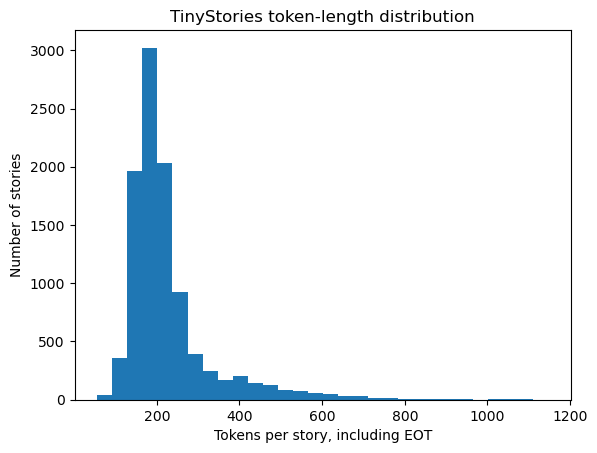

In [9]:
import matplotlib.pyplot as plt

plt.hist(story_lengths, bins=30)
plt.xlabel("Tokens per story, including EOT")
plt.ylabel("Number of stories")
plt.title("TinyStories token-length distribution")
plt.show()

In [ ]:
import torch
from pathlib import Path
from src.gpt.data import get_batch

train_path = Path("../data/train.bin")

B = 4
T = 512
generator = torch.Generator().manual_seed(42)

x, y = get_batch(
    train_path, B, T, generator, device="cpu"
)

print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Input dtype:", x.dtype)
print("Target dtype:", y.dtype)

assert x.shape == (B, T)
assert y.shape == (B, T)
assert x.dtype == torch.long
assert y.dtype == torch.long
assert torch.equal(y[:, :-1], x[:, 1:])

print("All checks passed!")


from tokenizers import Tokenizer

tok = Tokenizer.from_file("../data/tokenizer.json")

print(repr(tok.decode(x[0].tolist())))

ModuleNotFoundError: No module named 'src'